# Experiment design: a practical textbook

A subscription product team wants to test a new recommendation screen. Before
estimating its effect, we will validate the assignment and decide whether the
experiment can detect a commercially meaningful lift.

This is a **reading-and-doing guide**, not just an API demo. It combines design
intuition, formulas, executable HypEx code and interpretation of actual outputs.

## Learning objectives

By the end, you should be able to:

- distinguish pre-treatment diagnostics from outcome analysis;
- explain what homogeneity tests can and cannot establish;
- quantify imbalance with standardised mean differences;
- evaluate a randomisation procedure using repeated A/A splits;
- attach uncertainty to an empirical false-positive rate;
- choose an allocation and defend a sample-size calculation.

**Prerequisites:** basic means, variances and p-values. **Runtime:** about one minute.
All data are synthetic and generated locally with a fixed seed.

## How to read this notebook

1. [The design and its assumptions](#1.-a-small-but-realistic-pre-experiment-table)
2. [Semantic roles](#2.-roles-describe-meaning,-not-just-dtypes)
3. [One-assignment diagnostics](#3.-homogeneity-is-a-diagnostic,-not-a-green-light)
4. [Repeated A/A diagnostics](#4.-repeat-the-randomisation:-the-aa-null-laboratory)
5. [Power and sample size](#5.-plan-for-an-effect-that-matters)
6. [Production checklist](#6.-production-checklist)

**Notation.** $D_i\in\{0,1\}$ is treatment assignment, $X_i$ is a
pre-treatment covariate, $Y_i$ is an outcome, $\alpha$ is a significance
level, and $\pi$ is desired power. A subscript $c$ means control and $t$
means treatment.

> **Reading rule.** Code produces evidence; the surrounding text explains
> which assumption or estimand that evidence concerns. Do not reduce a
> result table to its `OK` column.

## 1. A small but realistic pre-experiment table

Revenue is skewed, conversion is binary, and customer segment affects the
baseline. Treatment is already assigned, but all columns below describe
the **pre-experiment** period. Using post-treatment columns here would
invalidate the diagnostics.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from hypex import AATest, HomogeneityTest
from hypex.dataset import (
    Dataset,
    FeatureRole,
    InfoRole,
    StratificationRole,
    TargetRole,
    TreatmentRole,
)
from hypex.executor import MinSampleSize

# A single generator makes every diagnostic below reproducible.
rng = np.random.default_rng(2026)
n_users = 2_000
segment = rng.choice(["new", "regular", "vip"], n_users, p=[0.3, 0.5, 0.2])
pre_revenue = rng.gamma(4, 25, n_users) + np.select(
    [segment == "new", segment == "regular", segment == "vip"],
    [0, 25, 80],
)
pre_conversion = rng.binomial(1, np.clip(0.08 + pre_revenue / 1_500, 0, 0.6))

df = pd.DataFrame(
    {
        "user_id": np.arange(n_users),
        "treat": rng.binomial(1, 0.5, n_users),
        "segment": segment,
        "pre_revenue": pre_revenue,
        "pre_conversion": pre_conversion,
        "pre_sessions": rng.poisson(8, n_users),
        "device": rng.choice(["ios", "android", "web"], n_users),
    }
)
df.head()

/Users/danilsamsutdinov/HypEx/.venv/lib/python3.11/site-packages/pyspark/pandas/__init__.py:50: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.
  warnings.warn(


,user_id,treat,segment,pre_revenue,pre_conversion,pre_sessions,device
0,0,0,new,97.207710,0,6,ios
1,1,0,regular,152.886526,0,1,ios
2,2,1,regular,95.022644,0,15,ios
3,3,0,regular,143.642938,0,7,web
4,4,0,regular,78.673448,0,7,web


In [2]:
df.groupby("treat").agg(
    users=("user_id", "size"),
    revenue=("pre_revenue", "mean"),
    conversion=("pre_conversion", "mean"),
)

,users,revenue,conversion
treat,,,
0,970,129.777044,0.163918
1,1030,128.659993,0.161165


### The causal object comes before the table schema

For user $i$, let $Y_i(1)$ and $Y_i(0)$ be the outcomes we would see with
and without the new screen. The observed outcome is

$$Y_i=D_iY_i(1)+(1-D_i)Y_i(0).$$

A design analysis asks whether $D$ is independent of pre-treatment $X$.
It must not use $Y$: checking balance on a post-treatment outcome can select
an assignment that hides the very effect we want to estimate.

We also rely on **SUTVA**: one user's treatment does not affect another
user's outcome, and each treatment version is well defined. Network effects
or shared accounts would require a different design, not another test.

## 2. Roles describe meaning, not just dtypes

- `TreatmentRole`: the assigned control/test indicator.
- `TargetRole`: metrics to compare; here they are strictly historical.
- `FeatureRole`: additional covariates checked by A/A tests.
- `StratificationRole`: variables within which randomisation is performed.
- `InfoRole`: identifiers and metadata excluded from calculations.

The same pipeline can therefore be reused after renaming physical columns:
executors search by role rather than hard-coded names.

In [3]:
data = Dataset(
    roles={
        "user_id": InfoRole(int),
        "treat": TreatmentRole(int),
        "segment": StratificationRole(str),
        "pre_revenue": TargetRole(float),
        "pre_conversion": TargetRole(int),
        "pre_sessions": FeatureRole(int),
        "device": FeatureRole(str),
    },
    data=df,
)
data.roles

{'user_id': Info(<class 'int'>),
 'treat': Treatment(<class 'int'>),
 'segment': Stratification(<class 'str'>),
 'pre_revenue': Target(<class 'float'>),
 'pre_conversion': Target(<class 'int'>),
 'pre_sessions': Feature(data_type=<class 'int'>),
 'device': Feature(data_type=<class 'str'>)}

## 3. Homogeneity is a diagnostic, not a green light

`HomogeneityTest` compares the actual assigned groups. The t-test targets
means; the KS-test compares whole distributions. For binary conversion,
the mean is the conversion rate.

In this A/A-style report, `OK` means **no statistically significant
difference was detected**. It does not prove that the distributions are
identical: absence of evidence is not evidence of absence.

In [4]:
homogeneity = HomogeneityTest().execute(data)
homogeneity.summary

,feature,group,control mean,test mean,difference,difference %,ci lower,ci upper,TTest pass,TTest p-value,KSTest pass,KSTest p-value
0,pre_revenue,1,129.777044,128.659993,-1.117051,-0.860746,-6.131488,3.897387,OK,0.662432,OK,0.162421
1,pre_conversion,1,0.163918,0.161165,-0.002752,-1.679184,-0.035126,0.029621,OK,0.867667,OK,1.000000


### How to read the homogeneity table

Each row is a `(metric, compared group)` pair. `control mean` and
`test mean` describe scale; `difference` and its confidence interval
describe magnitude; the t-test concerns mean equality, while the KS-test
concerns distributional equality.

The hypotheses are not interchangeable. A non-significant KS result does
not validate the mean, and a non-significant t-test can hide changed tails.
With $H_0:\mu_t-\mu_c=0$, the estimated standard error for independent
groups is

$$\widehat{\operatorname{se}}(\bar X_t-\bar X_c)=
\sqrt{s_t^2/n_t+s_c^2/n_c}.$$

The reported 95% interval is approximately
$\bar X_t-\bar X_c\pm1.96\,\widehat{\operatorname{se}}$.

Look at effect sizes and confidence intervals alongside p-values. With a
large sample, a tiny irrelevant difference can be significant; with a small
sample, an important imbalance can remain undetected.

Stratification makes balance on `segment` exact by construction, but it
does not guarantee balance on every other covariate.

### Add a scale-free balance measure

A p-value depends on sample size. The **standardised mean difference**
(SMD) expresses imbalance in pooled standard-deviation units:

$$\operatorname{SMD}(X)=
\frac{\bar X_t-\bar X_c}
{\sqrt{(s_t^2+s_c^2)/2}}.$$

A common screening rule is $|\operatorname{SMD}|<0.1$, with smaller values
preferred for strong prognostic variables. This is a heuristic, not a
hypothesis test: context and sample size still matter.

In [5]:
# Compute SMD on the original, pre-treatment assignment.
def standardized_mean_difference(frame, feature):
    control = frame.loc[frame.treat == 0, feature]
    test = frame.loc[frame.treat == 1, feature]
    pooled_sd = np.sqrt((control.var() + test.var()) / 2)
    return (test.mean() - control.mean()) / pooled_sd


smd = pd.DataFrame(
    {
        "SMD": {
            feature: standardized_mean_difference(df, feature)
            for feature in ["pre_revenue", "pre_conversion", "pre_sessions"]
        }
    }
)
smd["absolute SMD"] = smd.SMD.abs()
smd.round(4)

,SMD,absolute SMD
pre_revenue,-0.0195,0.0195
pre_conversion,-0.0075,0.0075
pre_sessions,-0.0164,0.0164


Read the sign as `test minus control`; its absolute value measures severity.
If a strong predictor of the outcome has meaningful imbalance, stratify or
rerandomise on pre-treatment information. Do not celebrate a small SMD on
an irrelevant variable while ignoring a large SMD on a prognostic one.

## 4. Repeat the randomisation: the A/A null laboratory

Under a valid A/A split there is no treatment effect. For a test with
significance level $\alpha=0.05$,

$$
\mathrm{FPR} = P(p < 0.05 \mid H_0) \approx 0.05,
$$

and valid p-values should look approximately uniform on $[0,1]$.
We run 200 stratified splits. `dry_test=True` additionally checks the
uniformity of t-test p-values. This is a diagnostic of the whole pipeline,
not just of one lucky split.

In [6]:
# Fixed seeds make the Monte Carlo table exactly reproducible.
# Welch's t-test avoids an unnecessary equal-variance assumption.
aa_result = AATest(
    n_iterations=200,
    random_states=range(200),
    stratification=True,
    equal_variance=False,
    dry_test=True,
).execute(data)

In [7]:
display(aa_result.summary)
aa_result.aa_score

,feature,group,TTest aa score,TTest best split,KSTest aa score,KSTest best split,Chi2Test aa score,Chi2Test best split,result,control mean,test mean,difference,difference %
0,device,test_1,None,None,None,None,OK,OK,OK,NaN,NaN,NaN,NaN
1,pre_conversion,test_1,OK,OK,OK,OK,None,None,OK,0.161128,0.163853,0.002725,1.691286
2,pre_revenue,test_1,OK,OK,OK,OK,None,None,OK,129.189780,129.213579,0.023800,0.018422
3,pre_sessions,test_1,OK,OK,OK,OK,None,None,OK,7.947633,7.881827,-0.065806,-0.827998


,score,p-value,pass
pre_revenue TTest test_1,0.95,0.269499,True
pre_conversion TTest test_1,0.95,0.895285,True
pre_sessions TTest test_1,0.95,NaN,True
pre_revenue KSTest test_1,0.95,NaN,True
pre_conversion KSTest test_1,0.95,NaN,True
pre_sessions KSTest test_1,0.95,NaN,True
device Chi2Test test_1,0.95,NaN,True


`score` is close to 0.95 when the observed rejection share is close to the
nominal 0.05. For the t-test rows, the displayed p-value comes from the
dry-test uniformity check; it is **not** the p-value of one A/B comparison.
Empty p-values for the other rows simply mean that dry-test currently
reports this extra check only for t-tests.

Let us calculate the empirical false-positive rates directly from the
public per-iteration table.

In [8]:
experiments = aa_result.experiments.raw_data
pvalue_columns = [
    column
    for column in experiments.columns
    if " p-value " in column and not column.startswith("mean ")
]
fpr_rows = []
for column in pvalue_columns:
    feature, test_name, *_ = column.split(" ")
    p_values = experiments[column].dropna()
    fpr_rows.append(
        {
            "feature": feature,
            "test": test_name,
            "iterations": len(p_values),
            "FPR": (p_values < 0.05).mean(),
            "expected": 0.05,
        }
    )

fpr = pd.DataFrame(fpr_rows).sort_values(["feature", "test"])
fpr.round(3)

,feature,test,iterations,FPR,expected
6,device,Chi2Test,200,0.000,0.05
4,pre_conversion,KSTest,200,0.000,0.05
1,pre_conversion,TTest,200,0.050,0.05
3,pre_revenue,KSTest,200,0.040,0.05
0,pre_revenue,TTest,200,0.050,0.05
5,pre_sessions,KSTest,200,0.010,0.05
2,pre_sessions,TTest,200,0.055,0.05


### A p-value is a random variable under the null

If a continuous test statistic has null CDF $F_0$, then
$P=F_0(T)$ satisfies $P\sim\operatorname{Uniform}(0,1)$. Therefore a
histogram far from uniform can reveal an invalid null model, dependence,
data leakage or a broken splitting implementation.

The empirical FPR is itself an estimate. After $R$ independent A/A runs
with $K$ rejections, $K\sim\operatorname{Binomial}(R,\alpha)$ under a
correctly calibrated test. A Wilson interval gives a useful uncertainty
range without relying on the poor approximation $K=0\Rightarrow\text{no error}$.

In [9]:
# Wilson score intervals for each empirical rejection rate.
def wilson_interval(rejections, iterations, z=1.96):
    proportion = rejections / iterations
    denominator = 1 + z**2 / iterations
    centre = (proportion + z**2 / (2 * iterations)) / denominator
    half_width = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / iterations + z**2 / (4 * iterations**2)
        )
        / denominator
    )
    return centre - half_width, centre + half_width


fpr["false positives"] = (fpr["FPR"] * fpr["iterations"]).astype(int)
fpr[["FPR lower", "FPR upper"]] = fpr.apply(
    lambda row: pd.Series(wilson_interval(row["false positives"], row["iterations"])),
    axis=1,
)
fpr.round(3)

,feature,test,iterations,FPR,expected,false positives,FPR lower,FPR upper
6,device,Chi2Test,200,0.000,0.05,0,0.000,0.019
4,pre_conversion,KSTest,200,0.000,0.05,0,0.000,0.019
1,pre_conversion,TTest,200,0.050,0.05,10,0.027,0.090
3,pre_revenue,KSTest,200,0.040,0.05,8,0.020,0.077
0,pre_revenue,TTest,200,0.050,0.05,10,0.027,0.090
5,pre_sessions,KSTest,200,0.010,0.05,2,0.003,0.036
2,pre_sessions,TTest,200,0.055,0.05,11,0.031,0.096


The interval addresses Monte Carlo uncertainty, not systematic bias.
Correlated iterations would make it too narrow. Conservative discrete
tests may reject less often than $\alpha$; a rate far above $\alpha$ is
usually a stronger warning than a rate near zero, but both deserve
inspection.

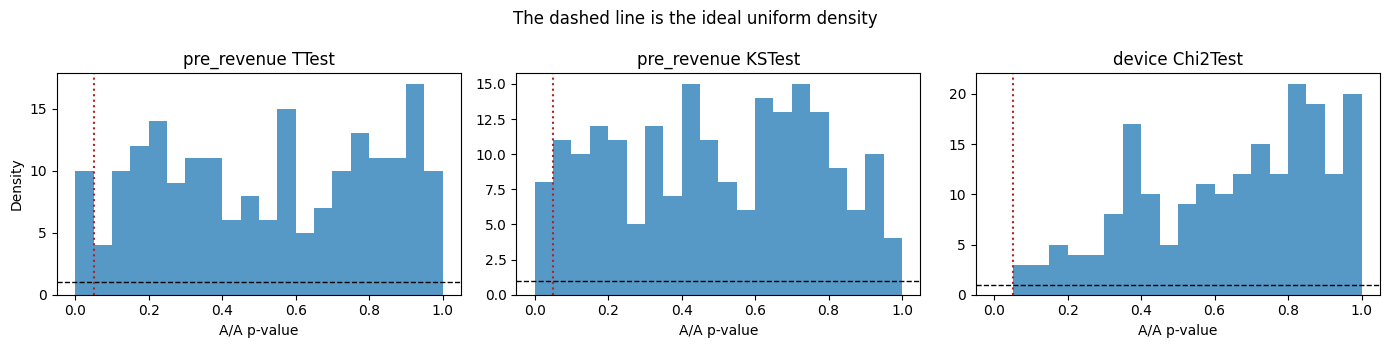

In [10]:
selected = [
    "pre_revenue TTest p-value test_1",
    "pre_revenue KSTest p-value test_1",
    "device Chi2Test p-value test_1",
]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column in zip(axes, selected):
    ax.hist(experiments[column].dropna(), bins=20, range=(0, 1), alpha=0.75)
    ax.axhline(1, color="black", linestyle="--", linewidth=1)
    ax.axvline(0.05, color="firebrick", linestyle=":", linewidth=1.5)
    ax.set_title(column.split(" p-value")[0])
    ax.set_xlabel("A/A p-value")
axes[0].set_ylabel("Density")
fig.suptitle("The dashed line is the ideal uniform density")
fig.tight_layout()
plt.show()

Do not expect exactly 5%: with 200 independent iterations, the Monte Carlo
standard error at the null is

$$\sqrt{0.05 \times 0.95 / 200} \approx 0.015.$$

Different tests and correlated metrics also make the rows non-independent.
Discrete test statistics can behave conservatively. Investigate systematic
inflation, an unexpectedly zero rate, or oddly shaped distributions rather
than overreacting to one decimal or treating the table as proof of validity.

> **Best-split caveat.** HypEx can reconstruct the highest-scoring split.
> This is useful for inspecting and repairing an assignment, but selecting
> a split using post-treatment outcomes would be cherry-picking. Use only
> pre-treatment information for this decision.

In [11]:
aa_result.best_split_statistics

,feature,group,control mean,test mean,difference,difference %,TTest pass,TTest p-value,KSTest pass,KSTest p-value,Chi2Test pass,Chi2Test p-value
0,device,test_1,NaN,NaN,NaN,NaN,None,NaN,None,NaN,OK,0.890799
1,pre_conversion,test_1,0.161128,0.163853,0.002725,1.691286,OK,0.868881,OK,1.000000,None,NaN
2,pre_revenue,test_1,129.189780,129.213579,0.023800,0.018422,OK,0.992590,OK,0.937688,None,NaN
3,pre_sessions,test_1,7.947633,7.881827,-0.065806,-0.827998,OK,0.599398,OK,0.722017,None,NaN


In [12]:
aa_result.best_split.data["split"].value_counts(normalize=True).rename("share")

split
test_1     0.5035
control    0.4965
Name: share, dtype: float64

### Unequal and multi-arm allocation

`groups_sizes` generalises the split beyond 50/50. Here 50% is control and
two treatment arms receive 25% each. Unequal allocation is valid, but the
smallest arm usually limits precision and power.

In [13]:
multi_arm = AATest(
    n_iterations=20,
    stratification=True,
    groups_sizes=[0.5, 0.25, 0.25],
).execute(data)
multi_arm.best_split.data["split"].value_counts().sort_index()

split
control    1014
test_1      487
test_2      499
Name: count, dtype: int64

For a fast assignment search, `early_stopping=True` can stop at an
acceptable split. Do not combine that with a false-positive-rate study:
stopping early truncates the p-value distribution. `sample_size` is useful
for large data because it subsamples before splitting.

## 5. Plan for an effect that matters

Statistical significance is not a business requirement. Suppose we want
80% power at two-sided $\alpha=0.05$ to detect an absolute revenue lift
$\delta=8$.

For two equally sized groups with common variance $\sigma^2$, the usual
normal approximation is

$$
n_{\text{per group}} \approx
\frac{2\sigma^2\left(z_{1-\alpha/2}-z_{1-\pi}\right)^2}{\delta^2},
\qquad \pi=0.8.
$$

`MinSampleSize` can estimate this from variances observed by treatment
group, or accept a variance supplied from a pilot. We pass the normal
quantiles explicitly to keep the example fast and transparent.

**API detail:** for this calculator, `power=0.2` denotes the lower normal
quantile level $1-\pi$, which corresponds to 80% power.

### Where the sample-size formula comes from

For equal group sizes $n$, the standard error of a mean difference is
$\sqrt{2\sigma^2/n}$. Rejecting when the observed difference exceeds
$z_{1-\alpha/2}$ standard errors and requiring the true effect $\delta$
to lie $z_{\pi}$ standard errors above that boundary gives

$$\delta=\left(z_{1-\alpha/2}+z_{\pi}\right)
\sqrt{2\sigma^2/n}.$$

Solving for $n$ yields the formula above. Since
$z_{\pi}=-z_{1-\pi}$, both forms are equivalent.

The calculation assumes independent observations, approximately normal
sampling errors, equal allocation and a common variance. Heavy tails,
clustering, unequal allocation, attrition and multiple primary hypotheses
all change the required design. A variance-reduced metric may use a lower
defensible $\sigma^2$, but only after validating that adjustment on
historical data.

In [14]:
planning_data = Dataset(
    roles={
        "treat": TreatmentRole(int),
        "pre_revenue": TargetRole(float),
    },
    data=df[["treat", "pre_revenue"]],
)
observed_variance = float(df["pre_revenue"].var())
calculator = MinSampleSize(
    mde=8.0,
    power=0.2,
    equal_variance=True,
    variances=observed_variance,
    quantile_1=float(norm.ppf(0.975)),
    quantile_2=float(norm.ppf(0.20)),
)
calculator.calc(planning_data)

{'pre_revenue': {'min sample size': 805}, 'overall': {'min sample size': 805}}

In [15]:
planning_rows = []
for variance_multiplier in [1.0, 1.5]:
    for effect in [5.0, 8.0, 12.0]:
        result = MinSampleSize(
            mde=effect,
            power=0.2,
            equal_variance=True,
            variances=observed_variance * variance_multiplier,
            quantile_1=float(norm.ppf(0.975)),
            quantile_2=float(norm.ppf(0.20)),
        ).calc(planning_data)
        planning_rows.append(
            {
                "variance multiplier": variance_multiplier,
                "MDE": effect,
                "users per group": result["overall"]["min sample size"],
            }
        )

pd.DataFrame(planning_rows).pivot(
    index="MDE", columns="variance multiplier", values="users per group"
)

variance multiplier,1.0,1.5
MDE,,
5.0,2060,3090
8.0,805,1207
12.0,358,537


### Absolute and relative MDE

`mde=8` is in revenue units, not percent. A product team usually thinks in
relative lift, so make the conversion explicit and record both in the
experiment specification.

In [16]:
baseline_mean = df.pre_revenue.mean()
mde_summary = pd.DataFrame(
    {
        "baseline mean revenue": [baseline_mean],
        "absolute MDE": [8.0],
        "relative MDE, %": [100 * 8.0 / baseline_mean],
        "observed users per group": [df.treat.value_counts().min()],
    }
)
mde_summary.round(2)

,baseline mean revenue,absolute MDE,"relative MDE, %",observed users per group
0,129.2,8.0,6.19,970


If the available group size is smaller than required, valid options include
recruiting more users, running longer, choosing a larger MDE, improving
variance reduction, or accepting lower power. Silently interpreting an
underpowered non-significant result as “no effect” is not a valid option.

The sensitivity table is more useful than one magic number: halving the
detectable effect roughly quadruples the required sample, while variance
enters linearly. Use a historically realistic variance, include expected
attrition, and account for multiple primary comparisons when relevant.

## Takeaways

- Validate assignment on **pre-treatment** columns only.
- Use homogeneity for one assignment and repeated A/A tests for the
  randomisation and testing pipeline.
- Interpret false-positive rates with Monte Carlo uncertainty.
- Stratify on strong prognostic variables; do not select splits using
  experimental outcomes.
- Plan around a minimum effect that is worth detecting, then stress-test
  the sample-size assumptions.

**Next:** [A/B/n inference and variance reduction](../ab/02_AB_Inference_and_Variance_Reduction.ipynb).

## 6. Production checklist

### Before launch

- [ ] Outcomes and covariates have unambiguous timestamps.
- [ ] The unit of randomisation matches the unit of independence.
- [ ] SUTVA and interference have been considered qualitatively.
- [ ] Balance is assessed by magnitude as well as tests.
- [ ] A/A iterations are reproducible and numerous enough for the question.
- [ ] The MDE, power, $\alpha$, allocation and comparison family are written
  down before outcome analysis.
- [ ] Attrition and missing data are included in the recruitment plan.